# Лабораторна робота №2. Baseline Classification Pipeline

In [105]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay, classification_report)

## 1. Завантажити та підготувати дані для навчання

In [106]:
train = pd.read_csv("train_lab2.csv")
test = pd.read_csv("test_lab2.csv")

print(train.shape)
print(test.shape)

train.head()

(307511, 122)
(48744, 121)


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


## 2. Відокремити цільову змінну від ознак

In [107]:
y = train["TARGET"]
X = train.drop(columns=["TARGET", "SK_ID_CURR"])
X_test = test.drop(columns=["SK_ID_CURR"])

print(y.value_counts(normalize=True))

TARGET
0    0.919271
1    0.080729
Name: proportion, dtype: float64


Клас 1 становить лише 8 %, тому accuracy тут не підходить і основна метрика ROC-AUC.

## 3. Розділити навчальні дані на навчальну та валідаційну вибірки (train-validation split)

In [108]:
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(X_train.shape, X_val.shape)

(246008, 120) (61503, 120)


## 4. Виконати базову обробку даних

### 4.1 Кодування категоріальних змінних (one-hot encoding)

In [109]:
X_train = pd.get_dummies(X_train)

X_val = pd.get_dummies(X_val).reindex(columns=X_train.columns, fill_value=0)
X_test = pd.get_dummies(X_test).reindex(columns=X_train.columns, fill_value=0)

print(X_train.shape, X_val.shape, X_test.shape)

(246008, 244) (61503, 244) (48744, 244)


### 4.2 Заповнення пропусків медіаною (медіана береться з train)

In [110]:
medians = X_train.median()

X_train = X_train.fillna(medians)
X_val = X_val.fillna(medians)
X_test = X_test.fillna(medians)

print(X_train.isna().sum().sum(), X_val.isna().sum().sum(), X_test.isna().sum().sum())

0 0 0


## 5. Навчити дерево рішень (Decision Tree Classifier) із параметрами за замовчуванням

In [111]:
model = DecisionTreeClassifier(min_samples_leaf=1200, class_weight="balanced", random_state=42)
model.fit(X_train, y_train)

print("Глибина дерева:", model.get_depth())
print("Кількість листків:", model.get_n_leaves())

Глибина дерева: 13
Кількість листків: 152


## 6. Оцінити якість моделі на валідаційній вибірці за метрикою ROC-AUC

ROC-AUC train: 0.7372
ROC-AUC validation: 0.7252


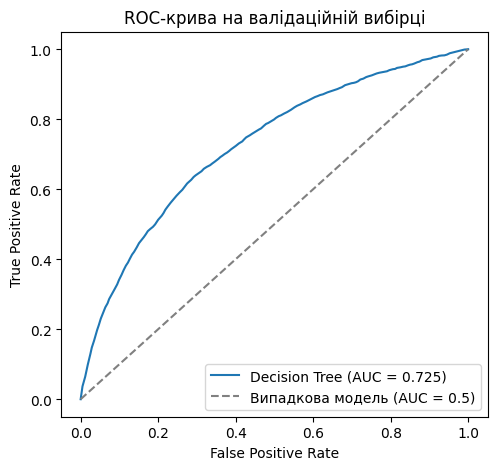

In [112]:
train_proba = model.predict_proba(X_train)[:, 1]
val_proba = model.predict_proba(X_val)[:, 1]

auc_train = roc_auc_score(y_train, train_proba)
auc_val = roc_auc_score(y_val, val_proba)
print(f"ROC-AUC train: {auc_train:.4f}")
print(f"ROC-AUC validation: {auc_val:.4f}")

fpr, tpr, _ = roc_curve(y_val, val_proba)
plt.figure(figsize=(5.5, 5))
plt.plot(fpr, tpr, label=f"Decision Tree (AUC = {auc_val:.3f})")
plt.plot([0, 1], [0, 1], "--", color="gray", label="Випадкова модель (AUC = 0.5)")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC-крива на валідаційній вибірці"); plt.legend(loc="lower right")
plt.show()

## 7. Побудувати матрицю помилок (Confusion Matrix) та провести аналіз помилок (Error Analysis)

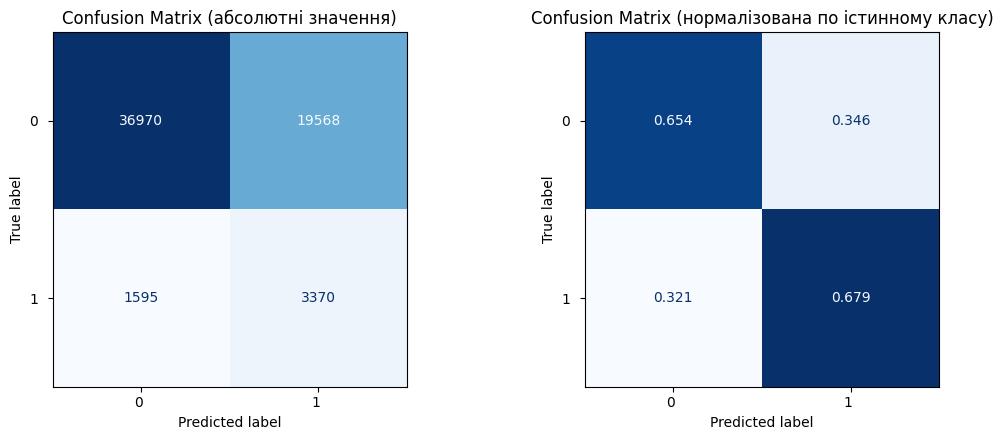

TN = 36970, FP = 19568, FN = 1595, TP = 3370

              precision    recall  f1-score   support

           0     0.9586    0.6539    0.7775     56538
           1     0.1469    0.6788    0.2416      4965

    accuracy                         0.6559     61503
   macro avg     0.5528    0.6663    0.5095     61503
weighted avg     0.8931    0.6559    0.7342     61503



In [114]:
val_pred = model.predict(X_val)
cm = confusion_matrix(y_val, val_pred)
tn, fp, fn, tp = cm.ravel()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay(cm, display_labels=["0 ", "1 "]).plot(ax=axes[0], cmap="Blues", values_format="d", colorbar=False)
axes[0].set_title("Confusion Matrix (абсолютні значення)")
ConfusionMatrixDisplay(confusion_matrix(y_val, val_pred, normalize="true"),
                       display_labels=["0 ", "1 "]).plot(ax=axes[1], cmap="Blues", values_format=".3f", colorbar=False)
axes[1].set_title("Confusion Matrix (нормалізована по істинному класу)")
plt.tight_layout(); plt.show()

print(f"TN = {tn}, FP = {fp}, FN = {fn}, TP = {tp}")
print()
print(classification_report(y_val, val_pred, target_names=["0", "1"], digits=4, zero_division=0))